# DL project


In [1]:
# Core data handling libraries
import numpy as np                             # numerical operations (numerical kaam ke liye)
import pandas as pd                              # tabular data handling (table wale data ke liye)

# Visualization libraries
import matplotlib.pyplot as plt                  # basic plotting (charts banane ke liye)
import seaborn as sns                             # statistical visualization (behtar visuals ke liye)

# Preprocessing and evaluation from scikit learn
from sklearn.model_selection import train_test_split          # splitting data (data split karne ke liye)
from sklearn.preprocessing import StandardScaler, LabelEncoder  # scaling and encoding (scaling aur encoding ke liye)
from sklearn.compose import ColumnTransformer                  # applying different transforms to different columns
from sklearn.pipeline import Pipeline                          # chaining preprocessing steps together
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, precision_recall_curve,
                              f1_score)                          # evaluation metrics (model check karne ke liye)
from sklearn.utils import class_weight                          # for handling class imbalance

# Deep learning libraries
import tensorflow as tf                          # main deep learning framework
from tensorflow import keras                     # high level API of TensorFlow
from tensorflow.keras import layers               # building blocks of neural network

# Reproducibility
import random
SEED = 42                                          # fixed seed so results are reproducible (same result har dafa aaye)
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)       # confirming TensorFlow is loaded correctly
print("GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)   # check karte hain GPU available hai ya nahi


TensorFlow version: 2.21.0
GPU Available: True


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [56]:
df = pd.read_excel("/content/drive/MyDrive/Data of Dl/Dry_Bean_Dataset.xlsx")                              # reading CSV directly from the internet (URL se data uthana)
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [22]:
df.isnull().sum()

,0
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


In [23]:
df['Class'].unique()

array(['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON'],
      dtype=object)

# Target class Distribution

/tmp/ipykernel_441/1280357264.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Class', palette='Set2')     # bar chart of churn vs not churn (churn distribution dekhna)


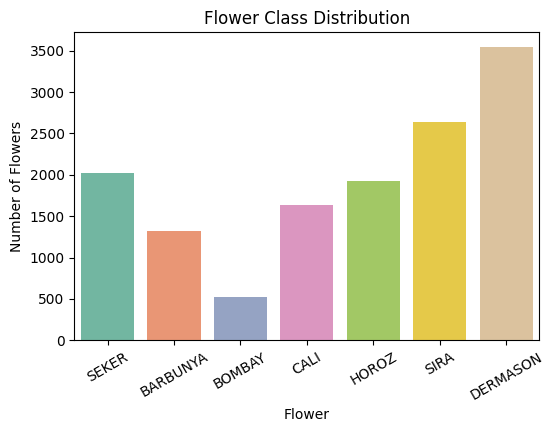

Class
DERMASON    26.052458
SIRA        19.366689
SEKER       14.892366
HOROZ       14.165014
CALI        11.975608
BARBUNYA     9.712732
BOMBAY       3.835133
Name: proportion, dtype: float64


In [24]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Class', palette='Set2')     # bar chart of churn vs not churn (churn distribution dekhna)
plt.title('Flower Class Distribution')
plt.xlabel('Flower')
plt.xticks(rotation=30)  # Naam ko 30 degree tircha karne ke liye
plt.ylabel('Number of Flowers')
plt.show()

churn_rate = df['Class'].value_counts(normalize=True) * 100   # percentage split of classes (percentage mein class split)
print(churn_rate)


# Numeric feature Distribution against class

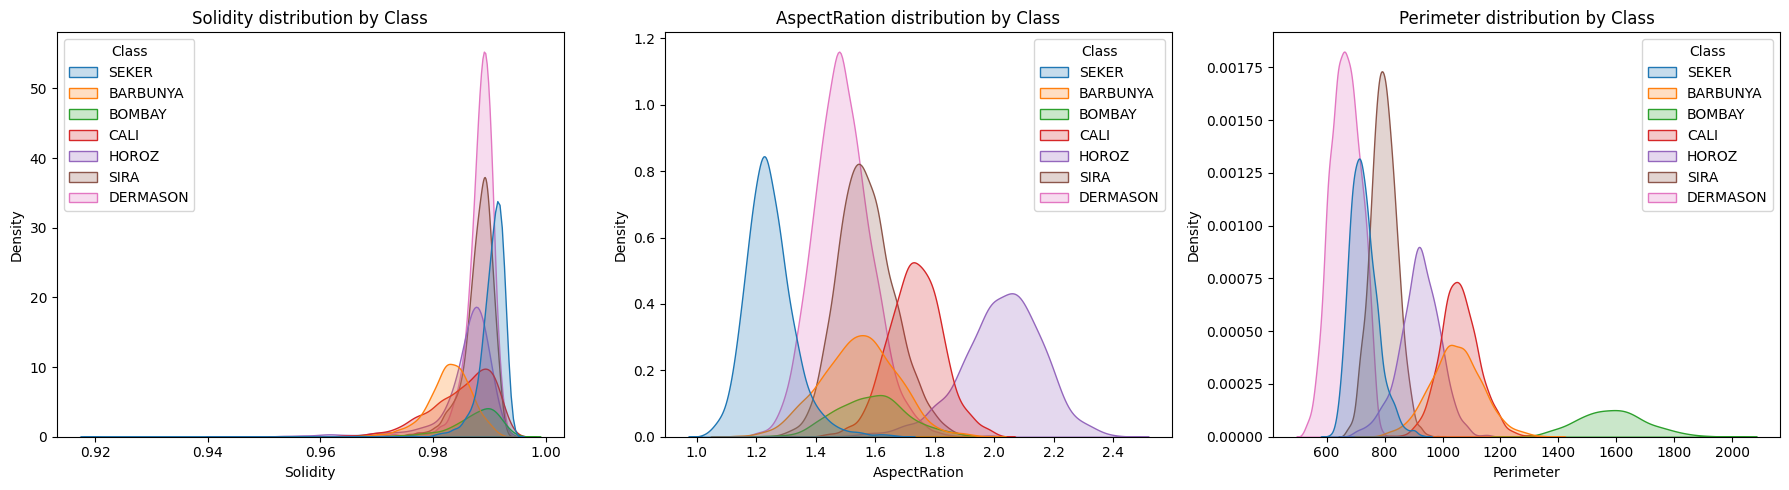

In [25]:
numeric_cols = ['Solidity', 'AspectRation', 'Perimeter']    # important numeric columns to inspect

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(numeric_cols):
    sns.kdeplot(data=df, x=col, hue='Class', fill=True, ax=axes[i])  # density plot split by churn (distribution churn ke hisab se)
    axes[i].set_title(f'{col} distribution by Class')
plt.tight_layout()
plt.show()


# Corelation Heatmap

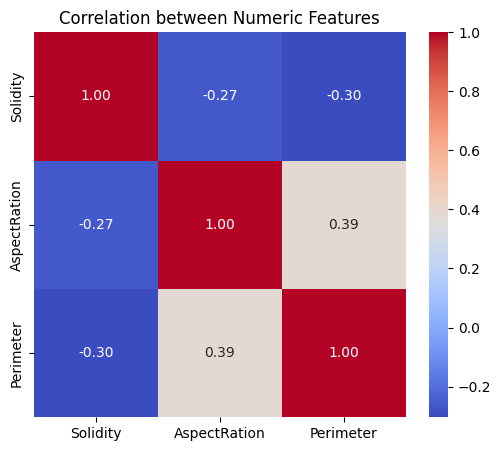

In [26]:
plt.figure(figsize=(6, 5))
corr = df[numeric_cols].corr()                       # correlation matrix (features ka aapas mein relation)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation between Numeric Features')
plt.show()


In [38]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


#Data cleaning

In [58]:
df['Class'] = df['Class'].map({'SEKER': 0, 'BARBUNYA': 1, 'BOMBAY': 2, 'CALI': 3,
                               'HOROZ': 4, 'SIRA': 5, 'DERMASON': 6})

X = df.drop('Class', axis=1)
y = df['Class']

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()   # numeric columns list
categorical_features = X.select_dtypes(include=['object']).columns.tolist()          # categorical columns list

In [59]:
y

,Class
0,0
1,0
2,0
3,0
4,0
...,...
13606,6
13607,6
13608,6
13609,6


#Train , validation and test split

In [60]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state = SEED, stratify = y)      # stratify keeps class ratio same in each split (class ratio barabar rakhna)

# Splitting temp into validation and test, equal halves
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print("Train size:", X_train.shape[0])
print("Validation size:", X_val.shape[0])
print("Test size:", X_test.shape[0])


Train size: 9527
Validation size: 2042
Test size: 2042


#Preprocessing pipline

In [61]:
# Building preprocessing pipeline for mixed data types
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),                       # scaling numeric columns (numeric ko scale karna)
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)  # encoding categorical columns (category ko number mein badalna)
])

# Fitting only on training data, then transforming all three sets
X_train_processed = preprocessor.fit_transform(X_train)     # fit and transform on train only (sirf train par fit karna)
X_val_processed = preprocessor.transform(X_val)               # transform validation using train statistics
X_test_processed = preprocessor.transform(X_test)             # transform test using train statistics

print("Processed training shape:", X_train_processed.shape)


Processed training shape: (9527, 16)


#SMOTE (Handling class imbalance)


In [62]:
from imblearn.over_sampling import SMOTE

# Applying SMOTE only on training data (sirf training data ko balance karna)
smote = SMOTE(random_state = SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)

print("Before SMOTE:", np.bincount(y_train))
print("After SMOTE:", np.bincount(y_train_smote))

Before SMOTE: [1419  925  365 1141 1350 1845 2482]
After SMOTE: [2482 2482 2482 2482 2482 2482 2482]


#Building Neural Network

In [63]:
# Defining input dimension based on processed features
input_dim = X_train_processed.shape[1]                # number of input features after preprocessing

def build_model(input_dim):
    model = keras.Sequential([                          # sequential stack of layers
        layers.Input(shape=(input_dim,)),                # input layer matching feature count

        layers.Dense(128, activation='relu'),                 # first hidden layer , 128 neuron
        layers.BatchNormalization(),                       # normalizing activations for stable training
        layers.Dropout(0.3),                                # dropping 30 percent neurons to reduce overfitting

        layers.Dense(64, activation='relu'),              # second hidden layer, 64 neurons
        layers.BatchNormalization(),                       # normalizing activations for stable training
        layers.Dropout(0.3),                                # dropping 30 percent neurons to reduce overfitting

        layers.Dense(32, activation='relu'),               # third hidden layer, 32 neurons
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(16, activation='relu'),               # fourth hidden layer, 16 neurons
        layers.Dropout(0.2),

        layers.Dense(7, activation='softmax')               # output layer, single neuron for binary classification
    ])
    return model

model = build_model(input_dim)
model.summary()                                            # printing architecture summary (model ka structure dekhna)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,055 (54.90 KB)

 Trainable params: 13,607 (53.15 KB)

 Non-trainable params: 448 (1.75 KB)

# COMPILING THE MODEL

In [64]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#Call back and Training


In [65]:
# Setting up training callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True),   # stop early if no improvement (improvement na ho to rukna)
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),       # reduce learning rate on plateau
    keras.callbacks.ModelCheckpoint(
        'best_model.keras', monitor='val_loss', save_best_only=True)    # save only the best model version
]

# Training the model
history = model.fit(
    X_train_smote, y_train_smote,
    validation_data=(X_val_processed, y_val),
    epochs=100,                                    # upper limit, early stopping will likely stop sooner
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
543/543 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.7486 - loss: 0.7323 - val_accuracy: 0.9216 - val_loss: 0.2310 - learning_rate: 0.0010
Epoch 2/100
543/543 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8773 - loss: 0.3992 - val_accuracy: 0.9324 - val_loss: 0.2087 - learning_rate: 0.0010
Epoch 3/100
543/543 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8925 - loss: 0.3491 - val_accuracy: 0.9344 - val_loss: 0.2045 - learning_rate: 0.0010
Epoch 4/100
543/543 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9015 - loss: 0.3311 - val_accuracy: 0.9324 - val_loss: 0.2032 - learning_rate: 0.0010
Epoch 5/100
543/543 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9066 - loss: 0.3145 - val_accuracy: 0.9310 - val_loss: 0.2044 - learning_rate: 0.0010
Epoch 6/100
543/543 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9092 - loss: 0.3060 - val_accuracy: 0.9314 - val_loss: 0.1934 - learning_rate: 0.0010
Epoch 7/100
543/543 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9154 - loss: 

#Model Evaluation on Test Set

In [70]:
# Generating predictions on the test set (7 classes)
y_pred_prob = model.predict(X_test_processed)            # shape: (2042, 7)
y_pred = np.argmax(y_pred_prob, axis=1)                  # har row ki sab se badi probability wali class (0 to 6)

# Printing full classification report
class_names = ['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
print(classification_report(y_test, y_pred, target_names = class_names))

# Multi-class ROC AUC score
auc_score = roc_auc_score(y_test, y_pred_prob, multi_class='ovr')
print(f"Test ROC AUC Score: {auc_score:.4f}")

64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
              precision    recall  f1-score   support

       SEKER       0.96      0.96      0.96       304
    BARBUNYA       0.95      0.95      0.95       199
      BOMBAY       1.00      1.00      1.00        78
        CALI       0.95      0.95      0.95       245
       HOROZ       0.97      0.96      0.96       289
        SIRA       0.86      0.91      0.89       395
    DERMASON       0.94      0.91      0.92       532

    accuracy                           0.93      2042
   macro avg       0.95      0.95      0.95      2042
weighted avg       0.94      0.93      0.94      2042

Test ROC AUC Score: 0.9961


#Confusion Matrix

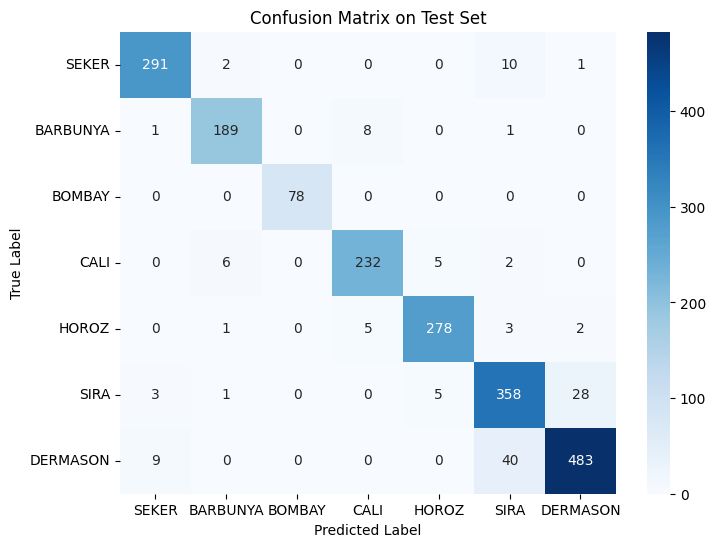

In [72]:
# Plotting confusion matrix
cm = confusion_matrix(y_test, y_pred)                       # computing confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON'],
            yticklabels=['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON'])
plt.title('Confusion Matrix on Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


#Roc curve

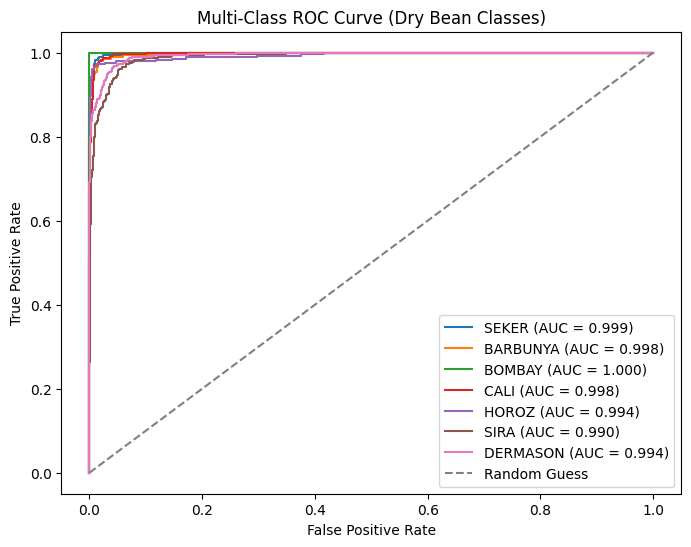

In [75]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

n_classes = len(class_names)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

plt.figure(figsize=(8, 6))
for i, name in enumerate(class_names):
    fpr_c, tpr_c, _ = roc_curve(y_test_bin[:, i], y_pred_prob[:, i])
    roc_auc_c = auc(fpr_c, tpr_c)
    plt.plot(fpr_c, tpr_c, label=f'{name} (AUC = {roc_auc_c:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curve (Dry Bean Classes)')
plt.legend(loc='lower right')
plt.show()

##Model Interpretability, Permutation Feature Importance

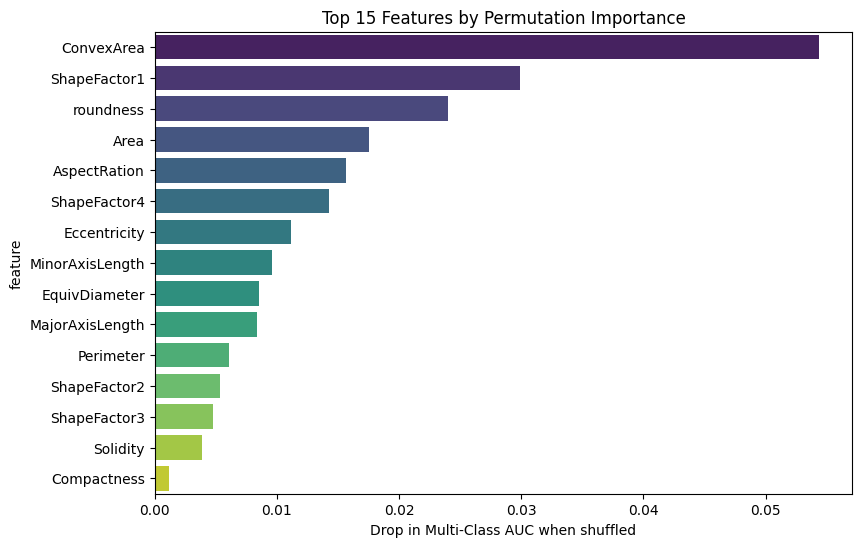

In [77]:
# Computing permutation importance manually for the multi-class neural network
def permutation_importance_nn(model, X, y_true, baseline_auc, feature_names, n_repeats=3):
    importances = []
    X_array = X.toarray() if hasattr(X, 'toarray') else np.array(X)

    for i in range(X_array.shape[1]):
        scores = []
        for _ in range(n_repeats):
            X_permuted = X_array.copy()
            np.random.shuffle(X_permuted[:, i])
            preds = model.predict(X_permuted, verbose=0)   # shape: (N, 7)
            score = roc_auc_score(y_true, preds, multi_class='ovr')
            scores.append(baseline_auc - score)
        importances.append(np.mean(scores))

    return importances

# Since all 16 features in Dry Bean dataset are numeric:
all_feature_names = numeric_features

# Running permutation importance
importances = permutation_importance_nn(model, X_test_processed, y_test, auc_score, all_feature_names, n_repeats=2)

importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, y='feature', x='importance', hue='feature', palette='viridis', legend=False)
plt.title('Top 15 Features by Permutation Importance')
plt.xlabel('Drop in Multi-Class AUC when shuffled')
plt.show()

#Save the model

In [78]:
import joblib                                        # for saving the sklearn pipeline

model.save('/content/drive/MyDrive/Data of Dl/Flower/Flower_model.keras')                        # saving full model architecture and weights

# Saving the preprocessing pipeline
joblib.dump(preprocessor,'/content/drive/MyDrive/Data of Dl/Flower/Flower_preprocessor.pkl')     # saving fitted preprocessor for consistent inference

print("Model and preprocessor saved successfully.")


Model and preprocessor saved successfully.


#Production Style Inference Function

In [83]:
def predict_flower(raw_df, model, preprocessor, class_names):
    """
    Takes a raw dataframe with the 16 numeric feature columns,
    applies the saved preprocessing pipeline, and returns the
    predicted class name and confidence score for each row.
    """
    processed = preprocessor.transform(raw_df)
    probabilities = model.predict(processed, verbose=0)        # shape: (N, 7)

    class_indices = np.argmax(probabilities, axis=1)           # sab se badi probability wali class index
    confidences = np.max(probabilities, axis=1)                # sab se badi probability ki value

    results = raw_df.copy()
    results['confidence'] = confidences.round(4)
    results['predicted_class'] = [class_names[i] for i in class_indices]
    return results

# Demonstrating inference on a small sample from the test set
sample_rows = X_test.iloc[:5]
prediction_output = predict_flower(sample_rows, model, preprocessor, class_names)

prediction_output[['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
                   'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
                   'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
                   'ShapeFactor3', 'ShapeFactor4', 'predicted_class', 'confidence']]

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,predicted_class,confidence
4185,67916,989.997,362.824428,240.028535,1.511589,0.749896,68706,294.063491,0.757146,0.988502,0.870792,0.810484,0.005342,0.001422,0.656885,0.992940,CALI,0.7428
2390,63888,1027.994,370.114112,221.098789,1.673976,0.801958,65071,285.209972,0.808832,0.981820,0.759710,0.770600,0.005793,0.001260,0.593825,0.994048,BARBUNYA,0.9992
4176,67766,996.422,392.893832,222.236767,1.767907,0.824652,69060,293.738576,0.684837,0.981263,0.857699,0.747628,0.005798,0.001117,0.558948,0.988168,CALI,0.9986
6741,56313,926.125,370.445000,194.935749,1.900344,0.850348,56975,267.768442,0.802545,0.988381,0.825048,0.722829,0.006578,0.001108,0.522482,0.992896,HOROZ,0.9876
9099,46160,810.790,308.952385,190.921049,1.618221,0.786207,46682,242.430892,0.810336,0.988818,0.882387,0.784687,0.006693,0.001565,0.615734,0.996393,SIRA,0.9852
